# 🎮 Modul 11 — Praktikum Sampling Distribution & Confidence Interval

### A/B Testing at Scale: Cookie Cats — 90.189 Pemain Game Mobile

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin
**Semester:** 5 · 3 SKS · CPMK072 (Sub-CPMK 072.2) · Milestone 3

---

## 🎯 Tujuan Pembelajaran

1. **Memahami** sampling distribution dan Standard Error melalui simulasi.
2. **Menghitung** CI untuk proporsi, selisih dua proporsi, dan bootstrap CI.
3. **Melakukan** power analysis untuk menentukan sample size sebelum eksperimen.
4. **Mengenali** jebakan A/B testing skala besar: SRM, peeking, banyak metrik.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Cookie Cats | 5 menit |
| **B** | EDA & Outlier | 10 menit |
| **C** | Simulasi Sampling Distribution & SE | 15 menit |
| **D** | CI Proporsi, Selisih & Bootstrap | 15 menit |
| **E** | z-test & SRM Check | 10 menit |
| **F** | Power Analysis & Sample Size | 10 menit |
| **G** | Simulasi Peeking Problem | 10 menit |
| **H** | Template Milestone 3 + Refleksi | 15 menit |

**Total: ± 90 menit**

---

## 💡 Konteks Eksperimen

**Cookie Cats** adalah game puzzle mobile. Pada level tertentu pemain menemui **gerbang** — harus menunggu atau membeli in-app purchase untuk lanjut. Developer menjalankan A/B test:

- **gate_30** (kontrol): gerbang di level 30
- **gate_40** (treatment): gerbang dipindah ke level 40

**Pertanyaan bisnis**: apakah memindahkan gerbang ke level 40 mengubah retensi pemain?

| Kolom | Arti |
|---|---|
| `userid` | ID pemain |
| `version` | grup eksperimen (gate_30 / gate_40) |
| `sum_gamerounds` | jumlah ronde dimainkan dalam 14 hari pertama |
| `retention_1` | kembali main 1 hari setelah install? (True/False) |
| `retention_7` | kembali main 7 hari setelah install? (True/False) |


---

# 🔧 A. Setup & Load Dataset


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
rng = np.random.default_rng(42)
ALPHA = 0.05
COLORS = {'gate_30': '#0284C7', 'gate_40': '#D97706'}

url = "https://raw.githubusercontent.com/ryanschaub/Mobile-Games-A-B-Testing-with-Cookie-Cats/master/cookie_cats.csv"
df = pd.read_csv(url)
for col in ['retention_1', 'retention_7']:
    df[col] = df[col].astype(int)   # True/False → 1/0 (Bernoulli)

A = df[df.version == 'gate_30']   # kontrol
B = df[df.version == 'gate_40']   # treatment
print(f"Total pemain : {len(df):,}")
print(f"gate_30      : {len(A):,}")
print(f"gate_40      : {len(B):,}")
df.head()


Total pemain : 90,189
gate_30      : 44,700
gate_40      : 45,489


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,0,0
1,337,gate_30,38,1,0
2,377,gate_40,165,1,0
3,483,gate_40,1,0,0
4,488,gate_40,179,1,1


---

# 🔍 B. EDA & Outlier


In [2]:
summary = df.groupby('version').agg(
    n=('userid', 'count'),
    retensi_1=('retention_1', 'mean'),
    retensi_7=('retention_7', 'mean'),
    ronde_mean=('sum_gamerounds', 'mean'),
    ronde_median=('sum_gamerounds', 'median'),
    ronde_max=('sum_gamerounds', 'max'),
)
summary[['retensi_1', 'retensi_7']] = (summary[['retensi_1', 'retensi_7']] * 100).round(2)
print("Retensi dalam persen:")
summary.round(2)


Retensi dalam persen:


,n,retensi_1,retensi_7,ronde_mean,ronde_median,ronde_max
version,,,,,,
gate_30,44700,44.82,19.02,52.46,17.0,49854
gate_40,45489,44.23,18.20,51.30,16.0,2640


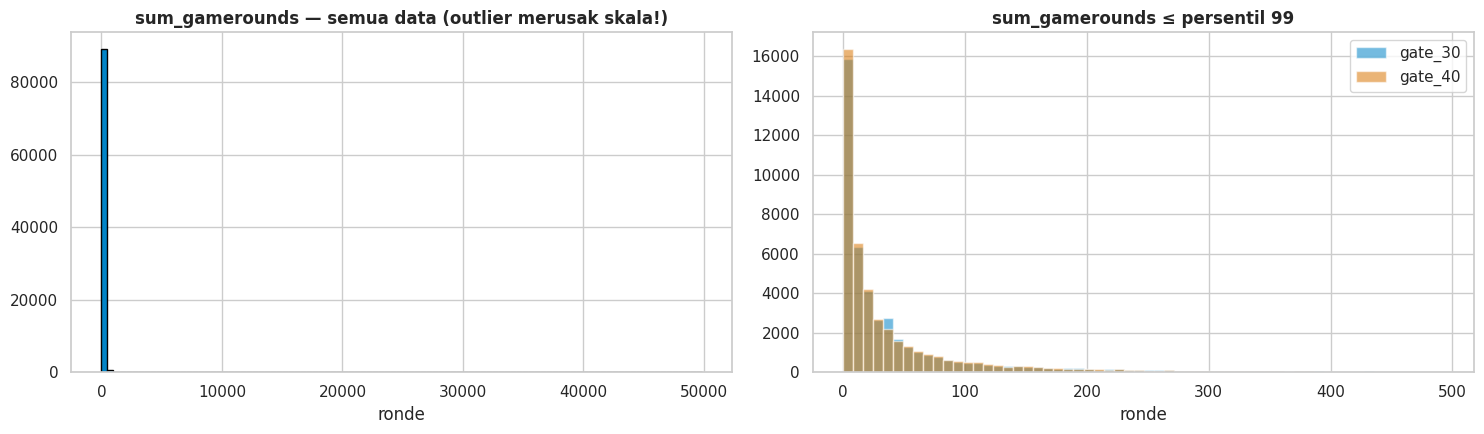

3 pemain dengan ronde terbanyak:
 userid version  sum_gamerounds
6390605 gate_30           49854
 871500 gate_30            2961
3271615 gate_40            2640

Persentil 99 = 493 ronde, tetapi maks = 49,854 ronde.
💡 Distribusi sangat skewed — mean mudah ditarik outlier, median lebih stabil.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(df['sum_gamerounds'], bins=100, color='#0284C7', edgecolor='black')
axes[0].set_title('sum_gamerounds — semua data (outlier merusak skala!)', fontweight='bold')
axes[0].set_xlabel('ronde')

clip = df[df.sum_gamerounds <= df.sum_gamerounds.quantile(0.99)]
for v, d in clip.groupby('version'):
    axes[1].hist(d['sum_gamerounds'], bins=60, alpha=0.55, color=COLORS[v], label=v)
axes[1].set_title('sum_gamerounds ≤ persentil 99', fontweight='bold')
axes[1].set_xlabel('ronde'); axes[1].legend()
plt.tight_layout(); plt.show()

top = df.nlargest(3, 'sum_gamerounds')[['userid', 'version', 'sum_gamerounds']]
print("3 pemain dengan ronde terbanyak:"); print(top.to_string(index=False))
print(f"\nPersentil 99 = {df.sum_gamerounds.quantile(0.99):.0f} ronde, tetapi maks = {df.sum_gamerounds.max():,} ronde.")
print("💡 Distribusi sangat skewed — mean mudah ditarik outlier, median lebih stabil.")


---

# 📐 C. Simulasi Sampling Distribution & Standard Error

**Tujuan Pembelajaran 1.** Kita anggap **seluruh 90.189 pemain sebagai populasi**, sehingga parameter populasinya diketahui. Lalu kita ambil sampel berulang kali dan amati distribusi statistiknya.

## C.1 Sampling distribution proporsi (retensi-7)

Teori: $SE(\hat{p}) = \sqrt{p(1-p)/n}$


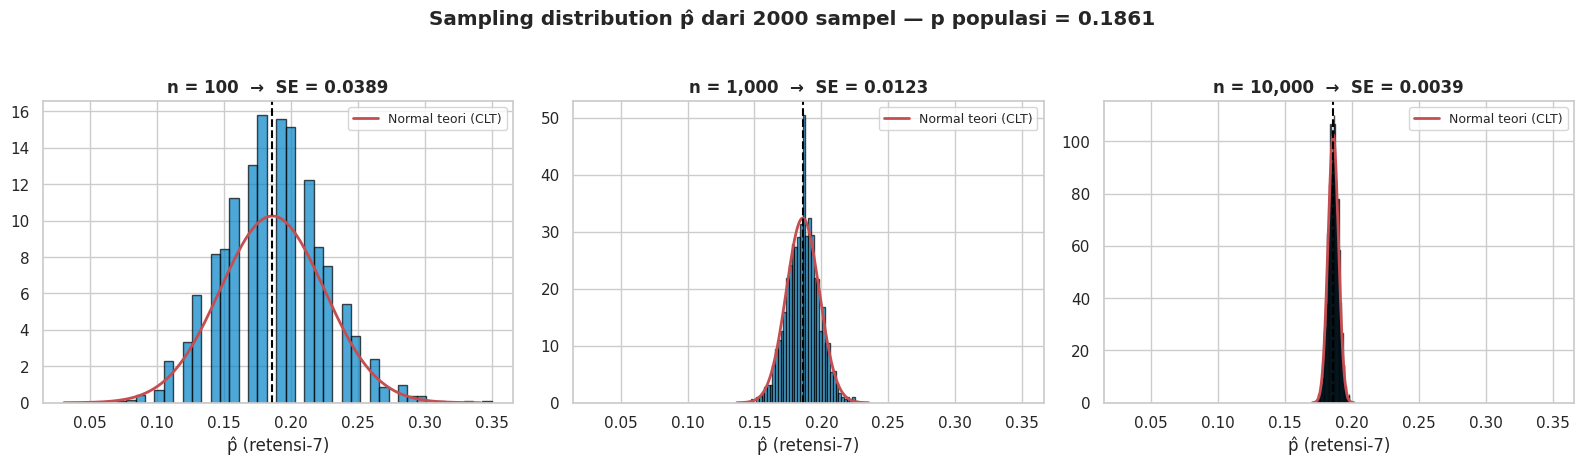

    n  SE empiris  SE teori
  100     0.03783   0.03892
 1000     0.01203   0.01231
10000     0.00383   0.00389

💡 n naik 10× → SE turun √10 ≈ 3.16×. Untuk SE setengahnya, butuh 4× data.


In [4]:
pop_r7 = df['retention_7'].values
p_true = pop_r7.mean()
REPS = 2000

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
rows = []
for ax, n in zip(axes, [100, 1_000, 10_000]):
    p_hats = rng.choice(pop_r7, size=(REPS, n), replace=True).mean(axis=1)
    se_theory = np.sqrt(p_true * (1 - p_true) / n)
    rows.append([n, p_hats.std(), se_theory])
    ax.hist(p_hats, bins=40, density=True, color='#0284C7', edgecolor='black', alpha=0.7)
    xs = np.linspace(p_true - 4*se_theory, p_true + 4*se_theory, 200)
    ax.plot(xs, stats.norm.pdf(xs, p_true, se_theory), 'r-', lw=2, label='Normal teori (CLT)')
    ax.axvline(p_true, color='black', ls='--')
    ax.set_title(f'n = {n:,}  →  SE = {se_theory:.4f}', fontweight='bold')
    ax.set_xlabel('p̂ (retensi-7)'); ax.legend(fontsize=9)
plt.suptitle(f'Sampling distribution p̂ dari {REPS} sampel — p populasi = {p_true:.4f}', y=1.03, fontweight='bold')
plt.tight_layout(); plt.show()

print(pd.DataFrame(rows, columns=['n', 'SE empiris', 'SE teori']).round(5).to_string(index=False))
print("\n💡 n naik 10× → SE turun √10 ≈ 3.16×. Untuk SE setengahnya, butuh 4× data.")


## C.2 Sampling distribution mean pada data sangat skewed (sum_gamerounds)

CLT tetap berlaku, tetapi **butuh n lebih besar** jika data sangat skewed.


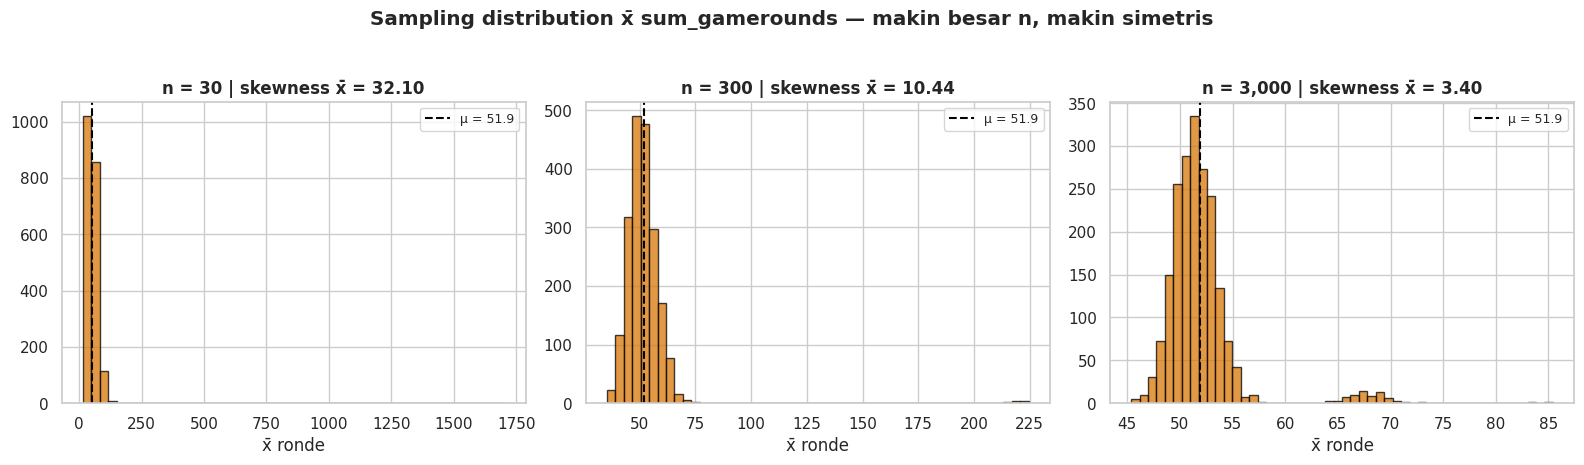

💡 Skewness mendekati 0 = makin mirip Normal. Pada n kecil, satu outlier bisa menggeser x̄ drastis.


In [5]:
pop_rounds = df['sum_gamerounds'].values
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, n in zip(axes, [30, 300, 3_000]):
    means = rng.choice(pop_rounds, size=(REPS, n), replace=True).mean(axis=1)
    ax.hist(means, bins=50, color='#D97706', edgecolor='black', alpha=0.75)
    ax.axvline(pop_rounds.mean(), color='black', ls='--', label=f'μ = {pop_rounds.mean():.1f}')
    ax.set_title(f'n = {n:,} | skewness x̄ = {stats.skew(means):.2f}', fontweight='bold')
    ax.set_xlabel('x̄ ronde'); ax.legend(fontsize=9)
plt.suptitle('Sampling distribution x̄ sum_gamerounds — makin besar n, makin simetris', y=1.03, fontweight='bold')
plt.tight_layout(); plt.show()
print("💡 Skewness mendekati 0 = makin mirip Normal. Pada n kecil, satu outlier bisa menggeser x̄ drastis.")


---

# 📏 D. Confidence Interval: Proporsi, Selisih & Bootstrap

**Tujuan Pembelajaran 2.**

## D.1 CI proporsi per grup — Wald vs Wilson


In [6]:
rows = []
for metric in ['retention_1', 'retention_7']:
    for name, g in [('gate_30', A), ('gate_40', B)]:
        k, n = g[metric].sum(), len(g)
        wald = proportion_confint(k, n, alpha=ALPHA, method='normal')
        wilson = proportion_confint(k, n, alpha=ALPHA, method='wilson')
        rows.append([metric, name, k/n*100, wald[0]*100, wald[1]*100, wilson[0]*100, wilson[1]*100])
ci_table = pd.DataFrame(rows, columns=['metrik', 'grup', 'p̂ %', 'Wald lo', 'Wald hi', 'Wilson lo', 'Wilson hi']).round(2)
print(ci_table.to_string(index=False))
print("\n💡 Dengan n ≈ 45.000, Wald dan Wilson praktis identik.")
print("   Perbedaan baru terasa saat n kecil atau p mendekati 0/1 (misal conversion rate 0.5%).")


     metrik    grup  p̂ %  Wald lo  Wald hi  Wilson lo  Wilson hi
retention_1 gate_30 44.82    44.36    45.28      44.36      45.28
retention_1 gate_40 44.23    43.77    44.68      43.77      44.69
retention_7 gate_30 19.02    18.66    19.38      18.66      19.39
retention_7 gate_40 18.20    17.85    18.55      17.85      18.56

💡 Dengan n ≈ 45.000, Wald dan Wilson praktis identik.
   Perbedaan baru terasa saat n kecil atau p mendekati 0/1 (misal conversion rate 0.5%).


## D.2 CI selisih proporsi (gate_30 − gate_40)

$$(\hat{p}_A - \hat{p}_B) \pm 1.96 \sqrt{\frac{\hat{p}_A(1-\hat{p}_A)}{n_A} + \frac{\hat{p}_B(1-\hat{p}_B)}{n_B}}$$


     metrik  selisih (poin %)    SE  CI lo  CI hi      Signifikan?
retention_1             0.591 0.331 -0.058  1.239 Tidak (memuat 0)
retention_7             0.820 0.259  0.312  1.328               Ya


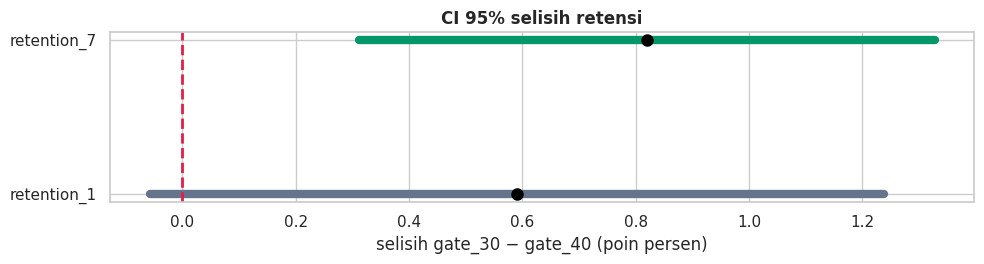

In [7]:
def ci_diff_prop(a, b, alpha=ALPHA):
    pa, pb = a.mean(), b.mean()
    se = np.sqrt(pa*(1-pa)/len(a) + pb*(1-pb)/len(b))
    z = stats.norm.ppf(1 - alpha/2)
    d = pa - pb
    return d, se, d - z*se, d + z*se

diff_rows = []
for metric in ['retention_1', 'retention_7']:
    d, se, lo, hi = ci_diff_prop(A[metric], B[metric])
    diff_rows.append([metric, d*100, se*100, lo*100, hi*100, 'Ya' if lo > 0 or hi < 0 else 'Tidak (memuat 0)'])
diff_table = pd.DataFrame(diff_rows, columns=['metrik', 'selisih (poin %)', 'SE', 'CI lo', 'CI hi', 'Signifikan?']).round(3)
print(diff_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 2.8))
for i, r in diff_table.iterrows():
    color = '#059669' if r['Signifikan?'] == 'Ya' else '#64748B'
    ax.plot([r['CI lo'], r['CI hi']], [i, i], color=color, lw=6)
    ax.plot(r['selisih (poin %)'], i, 'o', color='black', ms=8)
ax.axvline(0, color='#E11D48', ls='--', lw=2)
ax.set_yticks([0, 1]); ax.set_yticklabels(diff_table['metrik'])
ax.set_xlabel('selisih gate_30 − gate_40 (poin persen)')
ax.set_title('CI 95% selisih retensi', fontweight='bold')
plt.tight_layout(); plt.show()


## D.3 Bootstrap CI

Bootstrap tidak butuh rumus SE. Kita pakai untuk:
1. **Selisih retensi-7** — membandingkan dengan CI rumus di atas
2. **Selisih median ronde** — metrik yang tidak punya rumus SE sederhana


=== SELISIH RETENSI-7 (gate_30 − gate_40) ===
  Bootstrap CI 95% : [0.343, 1.346] poin %
  Rumus (Wald)     : [0.312, 1.328] poin %
  P(selisih > 0) dari bootstrap = 1.000

=== SELISIH MEDIAN RONDE (gate_30 − gate_40) ===
  Median gate_30 = 17, gate_40 = 16
  Bootstrap CI 95% : [0.0, 1.0] ronde


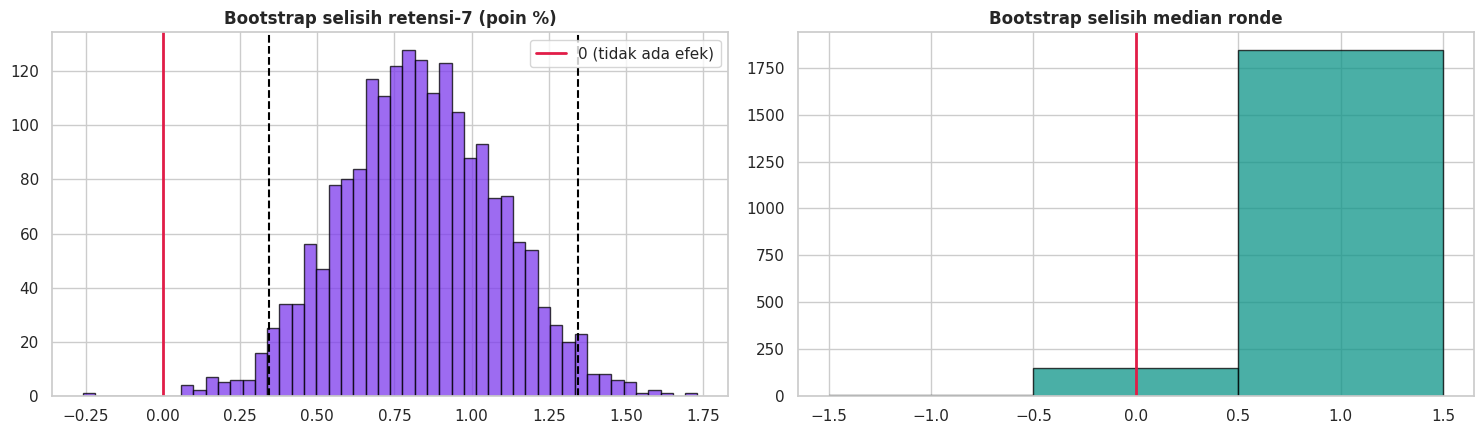

💡 Distribusi bootstrap median 'bergerigi' karena median data diskret selalu bilangan bulat/setengah.


In [8]:
B_REPS = 2000
a7, b7 = A['retention_7'].values, B['retention_7'].values
ar, br = A['sum_gamerounds'].values, B['sum_gamerounds'].values

boot_r7, boot_med = np.empty(B_REPS), np.empty(B_REPS)
for i in range(B_REPS):
    ia = rng.integers(0, len(a7), len(a7))
    ib = rng.integers(0, len(b7), len(b7))
    boot_r7[i] = a7[ia].mean() - b7[ib].mean()
    boot_med[i] = np.median(ar[ia]) - np.median(br[ib])

lo7, hi7 = np.percentile(boot_r7, [2.5, 97.5])
_, _, flo, fhi = ci_diff_prop(A['retention_7'], B['retention_7'])
print("=== SELISIH RETENSI-7 (gate_30 − gate_40) ===")
print(f"  Bootstrap CI 95% : [{lo7*100:.3f}, {hi7*100:.3f}] poin %")
print(f"  Rumus (Wald)     : [{flo*100:.3f}, {fhi*100:.3f}] poin %")
print(f"  P(selisih > 0) dari bootstrap = {(boot_r7 > 0).mean():.3f}")

lom, him = np.percentile(boot_med, [2.5, 97.5])
print("\n=== SELISIH MEDIAN RONDE (gate_30 − gate_40) ===")
print(f"  Median gate_30 = {np.median(ar):.0f}, gate_40 = {np.median(br):.0f}")
print(f"  Bootstrap CI 95% : [{lom:.1f}, {him:.1f}] ronde")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(boot_r7*100, bins=50, color='#7C3AED', edgecolor='black', alpha=0.75)
for v in [lo7*100, hi7*100]: axes[0].axvline(v, color='black', ls='--')
axes[0].axvline(0, color='#E11D48', lw=2, label='0 (tidak ada efek)')
axes[0].set_title('Bootstrap selisih retensi-7 (poin %)', fontweight='bold'); axes[0].legend()
axes[1].hist(boot_med, bins=np.arange(boot_med.min()-0.5, boot_med.max()+1.5, 1), color='#0D9488', edgecolor='black', alpha=0.75)
axes[1].axvline(0, color='#E11D48', lw=2)
axes[1].set_title('Bootstrap selisih median ronde', fontweight='bold')
plt.tight_layout(); plt.show()
print("💡 Distribusi bootstrap median 'bergerigi' karena median data diskret selalu bilangan bulat/setengah.")


---

# 🧪 E. z-test & Sample Ratio Mismatch (SRM) Check

## E.1 SRM check — LAKUKAN INI PERTAMA

Alokasi direncanakan 50:50. Jika rasio teramati menyimpang signifikan, kemungkinan ada **bug** pada randomisasi atau logging — dan semua hasil eksperimen jadi diragukan.

**H₀**: rasio alokasi = 50:50 (uji chi-square goodness-of-fit)


In [9]:
observed = [len(A), len(B)]
expected = [len(df) / 2] * 2
chi2, p_srm = stats.chisquare(observed, expected)

print("=== SRM CHECK ===")
print(f"  Observed : gate_30 = {observed[0]:,} ({observed[0]/len(df)*100:.2f}%), gate_40 = {observed[1]:,} ({observed[1]/len(df)*100:.2f}%)")
print(f"  Expected : {expected[0]:,.0f} per grup")
print(f"  χ² = {chi2:.3f}, p = {p_srm:.4f}")
if p_srm < 0.001:
    print("  🚨 SRM kuat — hentikan analisis, investigasi pipeline alokasi.")
elif p_srm < ALPHA:
    print("  ⚠️  Ada indikasi SRM (p < 0.05). Banyak tim memakai ambang lebih ketat (mis. p < 0.001)")
    print("     karena SRM check dijalankan terus-menerus. Catat sebagai risiko & cek ke tim engineering.")
else:
    print("  ✅ Tidak ada indikasi SRM.")
print("\n💡 Selisih 789 pemain terdengar kecil, tetapi pada skala 90.000 sudah terdeteksi oleh uji.")


=== SRM CHECK ===
  Observed : gate_30 = 44,700 (49.56%), gate_40 = 45,489 (50.44%)
  Expected : 45,094 per grup
  χ² = 6.902, p = 0.0086
  ⚠️  Ada indikasi SRM (p < 0.05). Banyak tim memakai ambang lebih ketat (mis. p < 0.001)
     karena SRM check dijalankan terus-menerus. Catat sebagai risiko & cek ke tim engineering.

💡 Selisih 789 pemain terdengar kecil, tetapi pada skala 90.000 sudah terdeteksi oleh uji.


## E.2 Two-proportion z-test

**H₀**: p_gate30 = p_gate40  **H₁**: p_gate30 ≠ p_gate40


In [10]:
test_rows = []
for metric in ['retention_1', 'retention_7']:
    counts = np.array([A[metric].sum(), B[metric].sum()])
    nobs = np.array([len(A), len(B)])
    z, p = proportions_ztest(counts, nobs)
    h = proportion_effectsize(counts[0]/nobs[0], counts[1]/nobs[1])
    test_rows.append([metric, counts[0]/nobs[0]*100, counts[1]/nobs[1]*100, z, p, h,
                      'Tolak H₀' if p < ALPHA else 'Gagal tolak H₀'])
tests = pd.DataFrame(test_rows, columns=['metrik', 'gate_30 %', 'gate_40 %', 'z', 'p-value', "Cohen's h", 'Keputusan'])
print(tests.round(4).to_string(index=False))
print("\n💡 Cohen's h ≈ 0.02 → efek SANGAT kecil secara standar statistik,")
print("   tetapi untuk game dengan jutaan pemain, 0.8 poin retensi bisa berarti banyak pemain & pendapatan.")


     metrik  gate_30 %  gate_40 %      z  p-value  Cohen's h      Keputusan
retention_1    44.8188    44.2283 1.7841   0.0744     0.0119 Gagal tolak H₀
retention_7    19.0201    18.2000 3.1644   0.0016     0.0211       Tolak H₀

💡 Cohen's h ≈ 0.02 → efek SANGAT kecil secara standar statistik,
   tetapi untuk game dengan jutaan pemain, 0.8 poin retensi bisa berarti banyak pemain & pendapatan.


---

# ⚡ F. Power Analysis & Sample Size

**Tujuan Pembelajaran 3.** Berapa pemain yang dibutuhkan untuk mendeteksi efek tertentu dengan α = 0.05 dan power = 0.80?


In [11]:
power = NormalIndPower()

def n_needed(p_base, mde_pts, alpha=ALPHA, pw=0.80):
    es = proportion_effectsize(p_base, p_base - mde_pts/100)
    return power.solve_power(effect_size=abs(es), alpha=alpha, power=pw, ratio=1.0)

base_r1, base_r7 = A['retention_1'].mean(), A['retention_7'].mean()
print("=== SAMPLE SIZE PER GRUP (α=0.05, power=0.80) ===")
for mde in [2.0, 1.0, 0.82, 0.59, 0.25]:
    print(f"  MDE {mde:>4} poin (retensi-7 base {base_r7*100:.1f}%) → n ≈ {n_needed(base_r7, mde):>10,.0f}")

n_r1 = n_needed(base_r1, 0.59)
achieved = power.solve_power(effect_size=abs(proportion_effectsize(base_r1, B['retention_1'].mean())),
                             nobs1=len(A), alpha=ALPHA, ratio=len(B)/len(A))
print(f"\nRetensi-1: selisih teramati 0.59 poin butuh ≈ {n_r1:,.0f} per grup.")
print(f"Tersedia ≈ {len(A):,} per grup → power yang dicapai hanya ≈ {achieved:.0%}.")
print("💡 Retensi-1 'tidak signifikan' bukan bukti tidak ada efek — eksperimennya UNDERPOWERED.")


=== SAMPLE SIZE PER GRUP (α=0.05, power=0.80) ===
  MDE  2.0 poin (retensi-7 base 19.0%) → n ≈      5,793
  MDE  1.0 poin (retensi-7 base 19.0%) → n ≈     23,684
  MDE 0.82 poin (retensi-7 base 19.0%) → n ≈     35,357
  MDE 0.59 poin (retensi-7 base 19.0%) → n ≈     68,626
  MDE 0.25 poin (retensi-7 base 19.0%) → n ≈    384,901

Retensi-1: selisih teramati 0.59 poin butuh ≈ 111,385 per grup.
Tersedia ≈ 44,700 per grup → power yang dicapai hanya ≈ 43%.
💡 Retensi-1 'tidak signifikan' bukan bukti tidak ada efek — eksperimennya UNDERPOWERED.


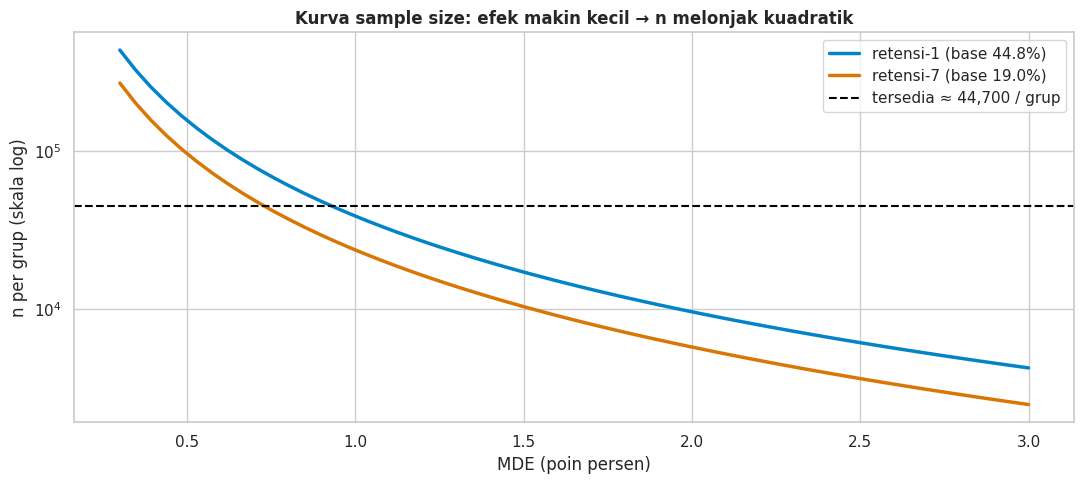

In [12]:
mdes = np.linspace(0.3, 3.0, 60)
fig, ax = plt.subplots(figsize=(11, 5))
for base, label, color in [(base_r1, f'retensi-1 (base {base_r1*100:.1f}%)', '#0284C7'),
                           (base_r7, f'retensi-7 (base {base_r7*100:.1f}%)', '#D97706')]:
    ax.plot(mdes, [n_needed(base, m) for m in mdes], lw=2.5, color=color, label=label)
ax.axhline(len(A), color='black', ls='--', label=f'tersedia ≈ {len(A):,} / grup')
ax.set_yscale('log'); ax.set_xlabel('MDE (poin persen)'); ax.set_ylabel('n per grup (skala log)')
ax.set_title('Kurva sample size: efek makin kecil → n melonjak kuadratik', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()


---

# 👀 G. Simulasi Peeking Problem

**Tujuan Pembelajaran 4.** Kita simulasikan **A/A test** — kedua grup identik (p = 0.20), jadi setiap "signifikan" adalah **false positive**.

- **Analis disiplin**: menguji SEKALI di akhir.
- **Analis tidak sabar**: cek p-value 20 kali selama eksperimen, berhenti begitu p < 0.05.


=== A/A TEST — tidak ada efek sama sekali ===
  Uji sekali di akhir          : false positive = 5.2%  (≈ α = 5%)
  Intip 20× & berhenti jika p<.05: false positive = 25.4%  🚨


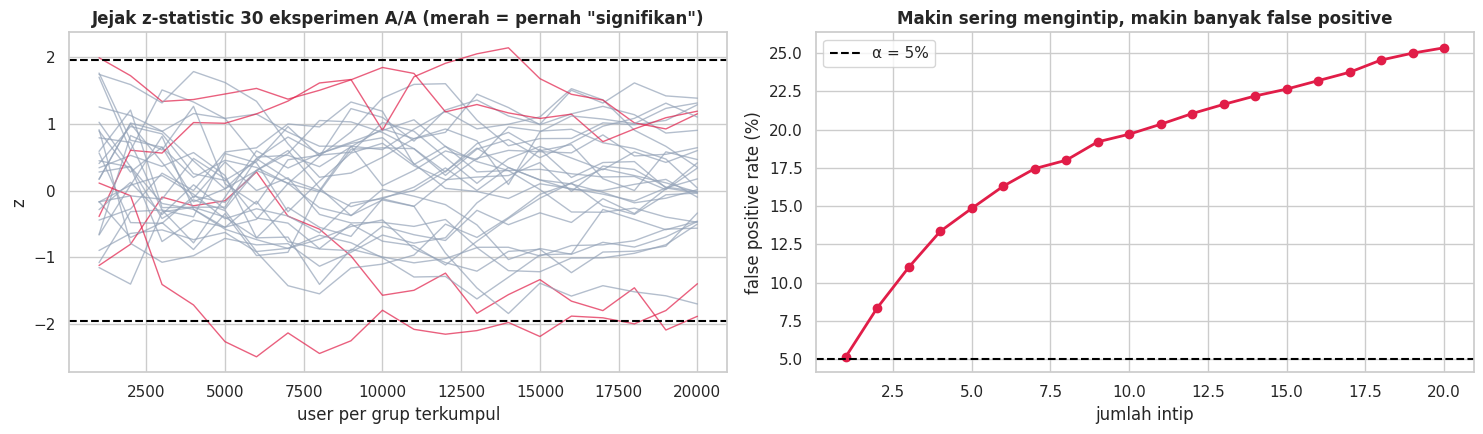

In [13]:
E, N, K, p0 = 2000, 20_000, 20, 0.20      # eksperimen, user/grup, jumlah intip, retensi
step = N // K
xa = rng.binomial(step, p0, (E, K)).cumsum(axis=1)
xb = rng.binomial(step, p0, (E, K)).cumsum(axis=1)
n_cum = np.arange(1, K + 1) * step
pa, pb = xa / n_cum, xb / n_cum
pp = (xa + xb) / (2 * n_cum)
z = (pa - pb) / np.sqrt(pp * (1 - pp) * 2 / n_cum)
sig = np.abs(z) > stats.norm.ppf(1 - ALPHA/2)

fp_final = sig[:, -1].mean()
fp_peek = sig.any(axis=1).mean()
print("=== A/A TEST — tidak ada efek sama sekali ===")
print(f"  Uji sekali di akhir          : false positive = {fp_final:.1%}  (≈ α = 5%)")
print(f"  Intip {K}× & berhenti jika p<.05: false positive = {fp_peek:.1%}  🚨")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for i in range(30):
    axes[0].plot(n_cum, z[i], color='#E11D48' if sig[i].any() else '#94A3B8', alpha=0.7, lw=1)
axes[0].axhline(1.96, color='black', ls='--'); axes[0].axhline(-1.96, color='black', ls='--')
axes[0].set_title('Jejak z-statistic 30 eksperimen A/A (merah = pernah "signifikan")', fontweight='bold')
axes[0].set_xlabel('user per grup terkumpul'); axes[0].set_ylabel('z')
cum_fp = [sig[:, :k].any(axis=1).mean() for k in range(1, K + 1)]
axes[1].plot(range(1, K + 1), np.array(cum_fp) * 100, 'o-', color='#E11D48', lw=2)
axes[1].axhline(5, color='black', ls='--', label='α = 5%')
axes[1].set_xlabel('jumlah intip'); axes[1].set_ylabel('false positive rate (%)')
axes[1].set_title('Makin sering mengintip, makin banyak false positive', fontweight='bold'); axes[1].legend()
plt.tight_layout(); plt.show()


## G.2 Keputusan Akhir Cookie Cats


In [14]:
d, se, lo, hi = ci_diff_prop(B['retention_7'], A['retention_7'])   # treatment − kontrol
print("=== REKOMENDASI ===")
print(f"Metrik utama  : retensi-7")
print(f"Efek gate_40  : {d*100:+.2f} poin, CI 95% [{lo*100:.2f}, {hi*100:.2f}]")
print(f"SRM check     : p = {p_srm:.4f}  (perlu dikonfirmasi ke tim engineering)")
print(f"Metrik sekunder: retensi-1 {tests.loc[0, 'p-value']:.3f} (tidak signifikan, underpowered)")
if hi < 0:
    print("\n❌ Seluruh CI di bawah 0 → JANGAN pindahkan gerbang ke level 40.")
    print("   Pertahankan gate_30, dengan catatan: konfirmasi dulu bahwa SRM bukan akibat bug.")


=== REKOMENDASI ===
Metrik utama  : retensi-7
Efek gate_40  : -0.82 poin, CI 95% [-1.33, -0.31]
SRM check     : p = 0.0086  (perlu dikonfirmasi ke tim engineering)
Metrik sekunder: retensi-1 0.074 (tidak signifikan, underpowered)

❌ Seluruh CI di bawah 0 → JANGAN pindahkan gerbang ke level 40.
   Pertahankan gate_30, dengan catatan: konfirmasi dulu bahwa SRM bukan akibat bug.


---

# 📝 H. Template Milestone 3 + Refleksi

## H.1 Template untuk Dataset Projek Anda

Dataset Anda mungkin bukan eksperimen A/B. Tidak apa-apa — pilih **2 grup penting** dari dataset Anda (misal: pelanggan premium vs reguler, wilayah A vs B) dan perlakukan sebagai perbandingan dua grup.


In [15]:
# =========================================================
# TEMPLATE MILESTONE 3 — ganti dengan dataset & kolom Anda
# =========================================================
# df_my = pd.read_csv("<URL dataset Milestone 1-2 Anda>")
# metric = '<kolom metrik utama>'          # numerik atau 0/1
# group_col, g1, g2 = '<kolom grup>', '<grup 1>', '<grup 2>'

# ---------- 1. Sampling distribution metrik utama ----------
# pop = df_my[metric].dropna().values
# for n in [30, 300, 3000]:
#     means = rng.choice(pop, size=(2000, n)).mean(axis=1)
#     print(n, means.std(), pop.std() / np.sqrt(n))   # SE empiris vs teori

# ---------- 2. CI rumus vs bootstrap ----------
# x1 = df_my.loc[df_my[group_col] == g1, metric].dropna().values
# x2 = df_my.loc[df_my[group_col] == g2, metric].dropna().values
# boot = [rng.choice(x1, len(x1)).mean() - rng.choice(x2, len(x2)).mean() for _ in range(2000)]
# print(np.percentile(boot, [2.5, 97.5]))

# ---------- 3. Power analysis ----------
# Tentukan MDE yang PENTING untuk bisnis, lalu:
# from statsmodels.stats.power import TTestIndPower      # untuk metrik numerik
# es = MDE / pooled_std                                   # Cohen's d
# print(TTestIndPower().solve_power(effect_size=es, alpha=0.05, power=0.8))

# ---------- 4. Rekomendasi (tabel 'Ship or Not' di slide) ----------
# Tulis di cell markdown: posisi CI terhadap 0 & MDE → keputusan + catatan risiko

print("💡 Copy template ini ke notebook projek Anda. Submit sebelum pertemuan Modul 12.")


💡 Copy template ini ke notebook projek Anda. Submit sebelum pertemuan Modul 12.


## H.2 Pertanyaan Refleksi

1. **Sampling distribution**: Jelaskan dengan bahasa sendiri perbedaan *distribusi sampel* dan *sampling distribution*. Mengapa sampling distribution retensi-7 berbentuk Normal padahal datanya hanya 0 dan 1?

2. **Bootstrap**: Bootstrap CI selisih retensi-7 hampir sama dengan CI rumus. Lalu kapan bootstrap benar-benar dibutuhkan? Berikan satu contoh metrik dari dunia aplikasi (e-commerce, ojek online, game) yang tidak punya rumus SE sederhana.

3. **Power**: Seorang PM berkata, "Retensi-1 tidak signifikan, jadi pemindahan gerbang tidak berpengaruh ke retensi-1." Tanggapi pernyataan ini dengan hasil Bagian F.

4. **SRM**: Jika SRM check menghasilkan p < 0.001, mengapa analisis z-test sebaiknya dihentikan dulu? Sebutkan 2 kemungkinan penyebab teknis SRM.

5. **Peeking**: Tim Anda ingin memantau dashboard A/B setiap hari. Bagaimana cara melakukannya tanpa terjebak peeking problem?

### ✏️ Jawaban Anda:

**1.** Distribusi sampel adalah sebaran data mentah dalam satu sampel (misalnya nilai 0/1 dari 1.000 pemain). Sampling distribution adalah sebaran sebuah statistik (misalnya proporsi retensi p̂) yang dihitung dari banyak sampel berulang. Sampling distribution retensi-7 berbentuk Normal walaupun datanya hanya 0 dan 1 karena Central Limit Theorem. p̂ adalah rata-rata dari n variabel Bernoulli, dan rata-rata dari n yang cukup besar akan mendekati Normal dengan pusat p dan SE = √(p(1−p)/n). Pada simulasi, makin besar n (100, 1.000, 10.000) kurvanya makin sempit dan makin mirip kurva Normal teori.

**2.** Bootstrap dibutuhkan ketika statistik yang ingin dianalisis tidak punya rumus SE sederhana, atau ketika data sangat skewed dan sampelnya kecil sehingga asumsi normal diragukan. Pada retensi-7, bootstrap CI [0,343; 1,346] hampir sama dengan CI rumus Wald [0,312; 1,328] karena n besar dan ada rumus yang valid. Bootstrap benar-benar berguna untuk selisih median ronde (median gate_30 = 17, gate_40 = 16, bootstrap CI [0,0; 1,0] ronde), yang tidak punya rumus SE sederhana. Contoh lain: median nilai pesanan di e-commerce, persentil 95 waktu tunggu driver di ojek online, atau rasio pendapatan per pemain di game.

**3.** Pernyataan PM itu keliru. Tidak signifikan tidak sama dengan tidak ada efek. Dari Bagian F, selisih retensi-1 yang teramati 0,59 poin membutuhkan sekitar 111.385 pemain per grup untuk dideteksi dengan power 80%, sedangkan data yang tersedia hanya sekitar 44.700 per grup, sehingga power yang dicapai hanya sekitar 43%. Artinya, jika efek 0,59 poin itu nyata, eksperimen ini punya peluang sekitar 57% untuk melewatkannya. Eksperimennya underpowered, jadi hasilnya belum bisa menyimpulkan bahwa pemindahan gerbang tidak berpengaruh pada retensi-1.

**4.** Jika SRM check menghasilkan p < 0,001, berarti pembagian pemain ke dua grup menyimpang dari rencana 50:50 dan kemungkinan ada masalah pada randomisasi atau logging. Kedua grup bisa jadi tidak lagi sebanding (ada kelompok pemain tertentu yang hilang atau berlebih di salah satu grup), sehingga selisih metrik tidak bisa dianggap murni efek perlakuan dan hasil z-test jadi tidak valid. Dua kemungkinan penyebab teknis: (a) bug pada sistem alokasi, misalnya pembagian grup berbasis hash user ID yang tidak seimbang; (b) kehilangan data logging yang berbeda antar versi, misalnya versi tertentu lebih sering crash atau event-nya gagal tercatat, atau trafik bot/filter yang hanya mengenai satu grup. Pada data Cookie Cats, hasil SRM adalah gate_30 = 44.700 (49,56%) dan gate_40 = 45.489 (50,44%) dengan χ² = 6,902 dan p = 0,0086. Itu indikasi SRM (p < 0,05) tetapi belum sekuat p < 0,001, sehingga perlu dicatat sebagai risiko dan dikonfirmasi ke tim engineering.

**5.** Memantau dashboard setiap hari boleh, asalkan tidak dipakai untuk memutuskan menghentikan eksperimen begitu p < 0,05. Pada simulasi A/A, analis yang menguji sekali di akhir mendapat false positive 5,2% (sesuai α = 5%), sedangkan yang mengintip 20 kali dan berhenti saat p < 0,05 mendapat false positive 25,4%. Caranya: (a) tentukan sample size dan durasi di awal dengan power analysis, lalu ambil keputusan hanya di akhir; (b) gunakan dashboard hanya untuk memantau kesehatan eksperimen (SRM, error, metrik guardrail) tanpa menyimpulkan efek; (c) jika memang perlu berhenti lebih awal, pakai metode sequential testing (misalnya alpha spending atau mSPRT) yang mengoreksi pengintipan berulang.


## H.3 Checklist Submit

### Praktikum (notebook ini)
- [ ] Semua cell berjalan tanpa error
- [ ] Tabel SE empiris vs teori untuk n = 100, 1.000, 10.000
- [ ] CI Wald vs Wilson + CI selisih retensi
- [ ] Bootstrap CI selisih retensi-7 & median ronde
- [ ] SRM check + z-test kedua metrik
- [ ] Kurva sample size & power retensi-1
- [ ] Simulasi peeking (false positive ≈ 5% vs jauh lebih tinggi)
- [ ] 5 pertanyaan refleksi dijawab

### Milestone 3 (notebook projek Anda)
- [ ] Simulasi sampling distribution 1 metrik utama
- [ ] CI rumus + bootstrap CI, dibandingkan
- [ ] CI selisih 2 grup penting
- [ ] Power analysis untuk MDE pilihan + evaluasi kecukupan data
- [ ] Rekomendasi keputusan + catatan risiko
- [ ] README diperbarui, commit: `"Milestone 3: sampling distribution & CI"`
- [ ] Link GitHub dikumpulkan via LMS **sebelum Modul 12**

---

## 🎓 Selamat! Anda Berhasil...

✅ Membuktikan SE = σ/√n lewat simulasi
✅ Menghitung CI proporsi, selisih, dan bootstrap CI
✅ Menentukan sample size dengan power analysis
✅ Mendeteksi SRM dan membuktikan bahaya peeking
✅ Membuat rekomendasi keputusan dari eksperimen 90.000 pemain

## 📚 Bacaan Lanjutan
- **Kohavi, R., Tang, D., & Xu, Y.** (2020). *Trustworthy Online Controlled Experiments: A Practical Guide to A/B Testing*. Cambridge University Press.
- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Ch. 2 (Sampling Distribution & Bootstrap).
- **Efron, B. & Tibshirani, R.** (1993). *An Introduction to the Bootstrap*.

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
